# 114 · 2 Token masking: which laser and frequency tokens does the transformer read?

**Tokenization** (`src9/arch/transformer.py`). Two stages, so a token is either joint or per laser:
1. **freq stage**: each laser's spectrum (1170 bins × 2 axes) is cut into **19 bands of 64 bins (~49 Hz)**. One token per **(laser, band)**:
   100 × 19 = 1900 tokens per sample. Each laser's 19 band tokens attend only to each other (2 blocks). An attention pool over the bands then
   makes **one token per laser**.
2. **laser stage**: the 100 laser tokens attend to each other (2 blocks), then LayerNorm → flatten → Linear(100·128 → 1024) → conv decoder.

**Removing a token**: key-padding mask, not zeroing the input. The cells below re-run the encoder layer by layer (src9 is not edited), with a
boolean `attn_mask` in `scaled_dot_product_attention`, so no other token can attend to the removed one. Its own output also has to be cut out
of the readout, because each stage reads every token (key-padding alone keeps the token's own residual stream):
- **band** (laser l, band j): masked as a key in laser l's freq blocks **and** in the attention pool (logit −∞, so pool weight 0 and the
  other bands renormalize). After that the token adds nothing to laser l's token.
- **freq band j**: the same, in all 100 lasers at once.
- **laser l**: masked as a key in the laser blocks **and** its slot in the flatten-Linear readout set to 0 (after the LayerNorm). That is
  exactly the model with that laser's token and its readout weights deleted.
  For comparison, `key-only` keeps the slot in the readout, so the laser still gets in through its own residual stream.

Δ = METRIC(masked) − METRIC(clean), per eval sample, then averaged. With `iou@0.08`, negative = the token helped. Eval set = the
setup's eval subset (up to 40 samples per eval split, every box), samples with an object only.

**Findings** (`s9-transformer-vase-1k` ep1000, 2166 eval samples over 65 eval splits, `iou@0.08` clean 0.464 in fp32, same as the run's saved eval 0.464)
- **No single laser matters.** Removing one laser token changes IoU by at most 0.0018 (~3 SEM). The top ones (51, 2, 9, 5, 75) are barely above
  noise, and the per-box maps disagree. Masking and train-mean occlusion agree only loosely per laser (ρ 0.49). The lasers are redundant.
- **Key-only masking does nothing (|Δ| ≤ 0.0002, ρ −0.04 with full masking).** No laser needs to *read* another one through attention. What a
  laser contributes goes through its own slot of the flatten-Linear readout. So "mask the key" alone is not a removal in this arch.
- **Every frequency band helps, and the high end helps most.** Removing one ~49 Hz band from all lasers costs 0.005 to 0.027 IoU. The top
  bands are 938-986 Hz (−0.027), 888-937 (−0.025), 642-691 (−0.019) and 199-247 (−0.017). The boxes differ: **cardboard** drives the
  high-frequency bands (−0.044 at 938-986), **plastic** the low ones (−0.028 at 199-247), and gastro is flatter. Occlusion gives nearly the
  same curve. The last band (987-1000 Hz, 18 real bins) matters little.
- **The joint (laser, band) map is noise-level** (cells ±0.0006, rank-1 share 0.12). Its band marginal does not track the all-laser band
  removal (ρ 0.05). When one laser loses a band, the other 99 cover for it. Band importance only shows up when the band is gone everywhere.

In [1]:
import os, sys, json, math
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9"))
import dataset as D9, utils as U, score
from arch.transformer import Transformer

RUN, CKPT, METRIC = "s9-transformer-vase-1k", "latest-rank0.pt", "iou@0.08"
N_TRAIN, N_PER_EVAL, SEED = 1000, 40, 0   # the nb114 shared cache's subset (00_setup): its eval rows are the eval set here
N_JOINT = 10**9                           # eval samples for the full (laser, band) matrix (1900 ablations each); all by default
SB = 8                                    # samples per GPU step (x 100-1900 ablations each)
DEV = "cuda"
OUT = ROOT / "notebooks/drafts_114/imp_masking.npz"
print(RUN, torch.cuda.mem_get_info())

s9-transformer-vase-1k (9982181376, 16608133120)


In [2]:
# eval samples: src9's own split, then the nb114 cache rows (same draw as 00_setup: N_TRAIN train, then up to N_PER_EVAL per eval split, rows sorted)
samples, idx = D9.load_splits()
metas, dirs = list(samples.values()), list(samples)
rng = np.random.default_rng(SEED)
pick = {int(i): "train" for i in rng.choice(idx["train"], N_TRAIN, replace=False)}
for name, ids in idx.items():
    if name != "train":
        for i in rng.choice(ids, min(N_PER_EVAL, len(ids)), replace=False): pick.setdefault(int(i), name)
order = sorted(pick)
X = np.load(ROOT / f"runs/_nb114_cache/{RUN}/X_{N_TRAIN}_{N_PER_EVAL}_{SEED}.npy", mmap_mode="r")   # (N,L,F,C) fp16 |fft|/std, read lazily
assert len(X) == len(order), "cache from another draw: run 00_setup"

sid = lambda m: int(m["sample_id"]) if m["sample_id"].isdigit() else -1           # as OutputSaver
ev = pd.DataFrame([dict(row=r, split=pick[i], box=metas[i]["box"], experiment=metas[i]["experiment"], sample_id=sid(metas[i]),
                        position_id=metas[i]["position_id"], speaker=metas[i]["speaker"]) for r, i in enumerate(order) if pick[i] != "train"])
# targets from src9's own scorer (BOX-downsampled 64x64, a with-lid sample takes its twin's mask); keep samples with an object
YT = torch.from_numpy(np.stack([score.truth(e, s, p, k, 64, 64) for e, s, p, k in zip(ev.experiment, ev.sample_id, ev.position_id, ev.speaker)]))
has = (YT > 0.5).flatten(1).any(1)
ev, YT = ev[has.numpy()].reset_index(drop=True), YT[has]

# check one cached row against src9's process_x
i = order[ev.row[0]]
x = next(D9.process_x({dirs[i]: metas[i]}, "tukey"))
print(f"cache vs process_x: max rel err {np.abs(X[ev.row[0]] - x).max() / np.abs(x).max():.1e};  {len(ev)} eval samples, {ev.split.nunique()} splits")

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

In [3]:
# model = the working-tree arch. The checkpoint has the flat pre-refactor names (encoder.embed, encoder.band_emb, encoder.lasers, ...): same
# weights and math, now nested in encoder.freq_enc / encoder.laser_enc (strict load catches any mismatch)
sd = torch.load(ROOT / f"runs/{RUN}/checkpoints/{CKPT}", map_location="cpu", weights_only=False)["state"]["model"]
NEW = dict(embed="freq_enc.embed", band_emb="freq_enc.freq_band_emb", box_emb="freq_enc.box_emb", freqs="freq_enc.freqs", pool_q="freq_enc.pool_q",
           pool_norm="freq_enc.pool_norm", pool_k="freq_enc.pool_k", pool_o="freq_enc.pool_o", lasers="laser_enc.lasers", to_emb="laser_enc.to_emb")
def rename(k): p = k.split("."); return ".".join([p[0], NEW[p[1]], *p[2:]]) if p[0] == "encoder" and p[1] in NEW else k
sd = {rename(k): v for k, v in sd.items()}
m0 = metas[0]
info = dict(n_laser_rows=m0["n_rows"], n_laser_cols=m0["n_cols"], n_freqs=X.shape[2], n_channels=X.shape[3], freq_range=(float(m0["min_freq"]), float(m0["max_freq"])),
            boxes=sorted({m["box"] for m in metas}), n_objects=sorted({m["n_objects"] for m in metas}),
            objects=sorted({"+".join(sorted(metas[i]["objects"])) for i in idx["train"]}) + ["unseen"],   # as build_dataset (sets the head sizes)
            cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].float() ** -2)            # buffers are overwritten by the load anyway
model = Transformer(info)
print(model.load_state_dict(sd, strict=True))
model = model.to(DEV).eval()
BOX = torch.tensor([info["boxes"].index(b) for b in ev.box])
R, Cc = info["n_laser_rows"], info["n_laser_cols"]; L = R * Cc                      # 10 x 10 lasers; laser l at (row l // Cc, col l % Cc) (grid_coords)
NB, BPB = len(model.encoder.freq_band_logf), model.encoder.freq_enc.bins_per_band  # 19 bands of 64 bins
FREQS = np.linspace(*info["freq_range"], X.shape[2])
BAND_LO, BAND_HI = FREQS[np.arange(NB) * BPB], FREQS[np.minimum(np.arange(1, NB + 1) * BPB, len(FREQS)) - 1]   # band edges, Hz (last band: 18 bins + padding)
xb = lambda s: torch.from_numpy(X[ev.row.values[s]].astype(np.float32)).to(DEV)  # eval samples s -> (B,L,F,C) raw spectrum on the GPU
del sd, samples, metas, dirs, idx, pick, order; import gc; gc.collect()                # ~1 GB of split metadata: not needed past here
print(f"L={L} ({R}x{Cc}), {NB} bands of {BPB} bins (~{FREQS[BPB] - FREQS[0]:.0f} Hz), {FREQS[0]:.0f}-{FREQS[-1]:.0f} Hz")

<All keys matched successfully>


L=100 (10x10), 19 bands of 64 bins (~49 Hz), 100-1000 Hz


In [4]:
# per-sample metrics on (B,64,64) mask probs vs truth (every sample here has an object); swap METRIC for any key
def iou_at(t): return lambda p, y: ((p > t) & (y > 0.5)).sum((1, 2)) / ((p > t) | (y > 0.5)).sum((1, 2)).clamp_min(1)
def miss_at(t): return lambda p, y: (~((p > t) & (y > 0.5)).flatten(1).any(1)).float()
METRICS = {"iou@0.08": iou_at(0.08), "miss@0.08": miss_at(0.08), "iou@0.5": iou_at(0.5)}
metric = METRICS[METRIC]

# clean forward = model(batch) as in eval (bf16 autocast), checked against src9's metric code and the run's own saved eval masks
with torch.no_grad(), torch.autocast("cuda", torch.bfloat16):
    P = torch.cat([model(dict(fft=xb(slice(s, s + 64)), box=BOX[s:s + 64].to(DEV)))["mask_pred"].float().cpu() for s in range(0, len(ev), 64)])
assert torch.allclose(METRICS["iou@0.08"](P, YT), U.iou08(dict(mask_pred=P), dict(mask_true=YT)))
assert torch.equal(METRICS["miss@0.08"](P, YT), U.miss08(dict(mask_pred=P), dict(mask_true=YT)))
want, saved = set(zip(ev.experiment, ev.sample_id, ev.position_id, ev.speaker)), {}
for f in (ROOT / f"runs/{RUN}/outputs_history/eval").glob(f"*/*/ep{score.last_epoch(RUN):04d}-*.pt"):
    d = torch.load(f, weights_only=False, map_location="cpu")
    for p, e, s, pos, k in zip(d["mask_pred"], d["info"]["experiment"], d["info"]["sample_id"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()):
        if (e, s, pos, k) in want: saved[e, s, pos, k] = p.float()
Ps = torch.stack([saved[e, s, p, k] for e, s, p, k in zip(ev.experiment, ev.sample_id, ev.position_id, ev.speaker)])
ev["clean"] = metric(P, YT).numpy()
print(f"vs saved ep{score.last_epoch(RUN)} masks: median |Δp| {(P - Ps).abs().amax((1, 2)).median():.1e}; {METRIC} {ev.clean.mean():.4f} here vs {metric(Ps, YT).mean():.4f} saved")
print(ev.groupby("box").clean.mean().round(3).to_dict())

vs saved ep1000 masks: median |Δp| 2.0e-02; iou@0.08 0.4639 here vs 0.4639 saved
{'cardboard': 0.421999990940094, 'gastronorm': 0.5109999775886536, 'green-plastic': 0.4869999885559082}


## 2.1 The encoder, layer by layer, with a keep mask
`block` = `Block.forward` plus a key-padding mask. `band_tokens` / `laser_tokens` / `mask_from` = `FreqEncoder` / `LaserEncoder` / decoder split at the
token boundaries. Check: with every token kept, this reproduces `model(batch)`.

In [5]:
E, FE, LE = model.encoder, model.encoder.freq_enc, model.encoder.laser_enc
with torch.no_grad(): LASER = E.laser_emb + E.laser_pos(E.laser_fourier)          # (L,d) laser identity + 2D position, as Encoder.forward

def block(blk, x, keep):  # Block.forward + key-padding mask: x (N,T,d), keep (N,T) bool, False = no query attends to that token
    N, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    x = x + blk.o(F.scaled_dot_product_attention(q, k, v, attn_mask=keep[:, None, None, :]).transpose(1, 2).reshape(N, T, D))
    return x + blk.mlp(blk.n2(x))

def band_tokens(xn, box):  # normalized (B,L,F,C) -> (B,L,NB,d) (laser, band) tokens: FreqEncoder.forward up to its blocks
    x = F.pad(xn, (0, 0, 0, NB * BPB - xn.shape[2])).view(len(xn), L, NB, -1)
    return FE.embed(x) + FE.freq_band_emb(E.freq_band_logf[:, None])[None, None] + LASER[None, :, None] + FE.box_emb(box)[:, None, None]

def laser_tokens(t, keep):  # (B,L,NB,d) + keep (B,L,NB) -> (B,L,d): freq blocks + band pool, the removed bands masked in both
    B = len(t)
    x = t.flatten(0, 1)
    for blk in FE.freqs: x = block(blk, x, keep.flatten(0, 1))
    x = x.view(B, L, NB, -1)
    k = FE.pool_k(FE.pool_norm(x)).view(B, L, NB, FE.heads, -1)
    a = (torch.einsum("blphe,he->blhp", k, FE.pool_q) / math.sqrt(k.shape[-1])).masked_fill(~keep[:, :, None], -torch.inf).softmax(-1)  # removed band: weight 0
    return FE.pool_o((x * a.mean(2)[..., None] * NB).reshape(B, L, -1)) + LASER

def mask_from(z, keep, drop_slot=True):  # (N,L,d) laser tokens + keep (N,L) -> (N,64,64) mask prob: laser blocks, readout, decoder
    for blk in LE.lasers: z = block(blk, z, keep)
    z = LE.to_emb[0](z)                                                            # the readout's LayerNorm
    if drop_slot: z = z * keep[..., None]                                          # removed laser: its slot of the flatten-Linear reads 0
    return model.decoder(LE.to_emb[2](z.flatten(1)))[:, 0].float().sigmoid()

CHUNK = 256  # decoder batch (fp32: ~1 GB of activations)
def decode(z, keep, drop_slot=True): return torch.cat([mask_from(z[s:s + CHUNK], keep[s:s + CHUNK], drop_slot) for s in range(0, len(z), CHUNK)])

KEEP = torch.ones(1, L, NB, dtype=torch.bool, device=DEV)                        # every token kept
# exactness check in fp32 (the ablations below run in fp32 too: bf16 noise flips pixels at the 0.08 threshold, and single-token Δs are small)
with torch.no_grad():
    x, bx = xb(slice(0, 64)), BOX[:64].to(DEV)
    p = decode(laser_tokens(band_tokens(E.normalize(x, bx), bx), KEEP.expand(64, -1, -1)), KEEP[:, :, 0].expand(64, -1))
    p_ref = model(dict(fft=x, box=bx))["mask_pred"]
print(f"all tokens kept vs model(batch), fp32: max |Δp| {(p - p_ref).abs().max():.1e};  fp32 vs the bf16 eval masks: {METRIC} {metric(p.cpu(), YT[:64]).mean():.4f} vs {metric(P[:64], YT[:64]).mean():.4f}")

all tokens kept vs model(batch), fp32: max |Δp| 1.3e-03;  fp32 vs the bf16 eval masks: iou@0.08 0.4244 vs 0.4250


## 2.2 Every ablation, batched (fp32)
Per step of `SB` samples: the (laser, band) tokens once; the freq stage once clean (`z0`) and once per removed band (`zb`, band j gone in every laser).
Then everything left is the laser stage + decoder on stacks of laser tokens:
- **laser l**: `z0`, keep = all but l (100 per sample), and the same with the readout slot kept (**key-only**)
- **band j**: `zb[:, j]`, keep all (19 per sample)
- **(laser l, band j)**: `z0` with row l swapped for `zb[:, j, l]`, since removing band j from laser l only changes laser l's token
  (1900 per sample, the first `N_JOINT` samples of a fixed shuffle; all of them by default)

Second baseline, **occlusion**: the token stays but its input is the box's train mean (`encoder.cum_mean[box]`, so the normalized input is
exactly 0), for a laser (all its bands) or for a band (in every laser). Occlusion asks "what if this laser/band said nothing unusual", masking
asks "what if it were not there".

In [6]:
import time
N = len(ev)
PERM = np.random.default_rng(SEED).permutation(N)                                  # joint matrix: the first N_JOINT of these
NOT_L = ~torch.eye(L, dtype=torch.bool, device=DEV)                               # (L,L): row l = every laser but l
NOT_B = ~torch.eye(NB, dtype=torch.bool, device=DEV)                              # (NB,NB): row j = every band but j
ALL_L, ar = torch.ones(1, L, dtype=torch.bool, device=DEV), torch.arange(L, device=DEV)
M0 = np.zeros(N)                                                                   # clean METRIC (fp32)
D_LASER, D_KEYONLY, D_OCC_LASER = np.zeros((N, L)), np.zeros((N, L)), np.zeros((N, L))   # Δ METRIC per sample: masked, key-only, occluded
D_BAND, D_OCC_BAND = np.zeros((N, NB)), np.zeros((N, NB))
D_JOINT = np.full((N, L, NB), np.nan)
t0 = time.time()
with torch.no_grad():
    for s in range(0, N, SB):
        ids = PERM[s:s + SB]; b = len(ids)
        y, bx = YT[ids].to(DEV), BOX[ids].to(DEV)
        t = band_tokens(E.normalize(xb(ids), bx), bx)                                                  # (b,L,NB,d)
        t_occ = band_tokens(torch.zeros(b, L, X.shape[2], X.shape[3], device=DEV), bx)                  # input = the box's train mean (normalized 0)
        z0 = laser_tokens(t, KEEP.expand(b, -1, -1))                                                   # (b,L,d) clean laser tokens
        zb = torch.stack([laser_tokens(t, NOT_B[j].expand(b, L, -1)) for j in range(NB)], 1)          # (b,NB,L,d) band j removed in every laser
        zo = laser_tokens(t_occ, KEEP.expand(b, -1, -1))                                               # (b,L,d) each laser's token with its input occluded
        zob = torch.stack([laser_tokens(torch.where((torch.arange(NB, device=DEV) == j)[:, None], t_occ, t), KEEP.expand(b, -1, -1)) for j in range(NB)], 1)  # band j occluded everywhere
        m0 = metric(decode(z0, ALL_L.expand(b, -1)), y)                                                # (b,)
        M0[ids] = m0.cpu().numpy()
        def delta(z, keep, k, **kw): return (metric(decode(z, keep, **kw), y.repeat_interleave(k, 0)).view(b, k) - m0[:, None]).cpu().numpy()
        def swap(new):  # (b,L,d) -> (b*L,L,d): copy l = z0 with laser l's token replaced by new[:, l]
            z = z0[:, None].repeat(1, L, 1, 1); z[:, ar, ar] = new; return z.flatten(0, 1)
        zl = z0[:, None].expand(b, L, L, -1).flatten(0, 1)                                              # (b*L,L,d), sample-major; keep row l = all but laser l
        D_LASER[ids] = delta(zl, NOT_L.repeat(b, 1), L)
        D_KEYONLY[ids] = delta(zl, NOT_L.repeat(b, 1), L, drop_slot=False)
        D_OCC_LASER[ids] = delta(swap(zo), ALL_L.expand(b * L, -1), L)
        D_BAND[ids] = delta(zb.flatten(0, 1), ALL_L.expand(b * NB, -1), NB)
        D_OCC_BAND[ids] = delta(zob.flatten(0, 1), ALL_L.expand(b * NB, -1), NB)
        if s < N_JOINT:                                                                                 # band j removed from laser l only
            for j in range(NB): D_JOINT[ids, :, j] = delta(swap(zb[:, j]), ALL_L.expand(b * L, -1), L)
        if (s // SB) % 50 == 0: print(f"{s + b}/{N} samples, {time.time() - t0:.0f} s, GPU peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
J = PERM[:N_JOINT]
print(f"done in {time.time() - t0:.0f} s; clean {METRIC}: {M0.mean():.4f} fp32 here vs {ev.clean.mean():.4f} bf16 eval")

8/2166 samples, 1 s, GPU peak 1.2 GB


408/2166 samples, 78 s, GPU peak 1.2 GB


808/2166 samples, 155 s, GPU peak 1.2 GB


1208/2166 samples, 230 s, GPU peak 1.2 GB


1608/2166 samples, 306 s, GPU peak 1.2 GB


2008/2166 samples, 383 s, GPU peak 1.2 GB


done in 414 s; clean iou@0.08: 0.4640 fp32 here vs 0.4639 bf16 eval


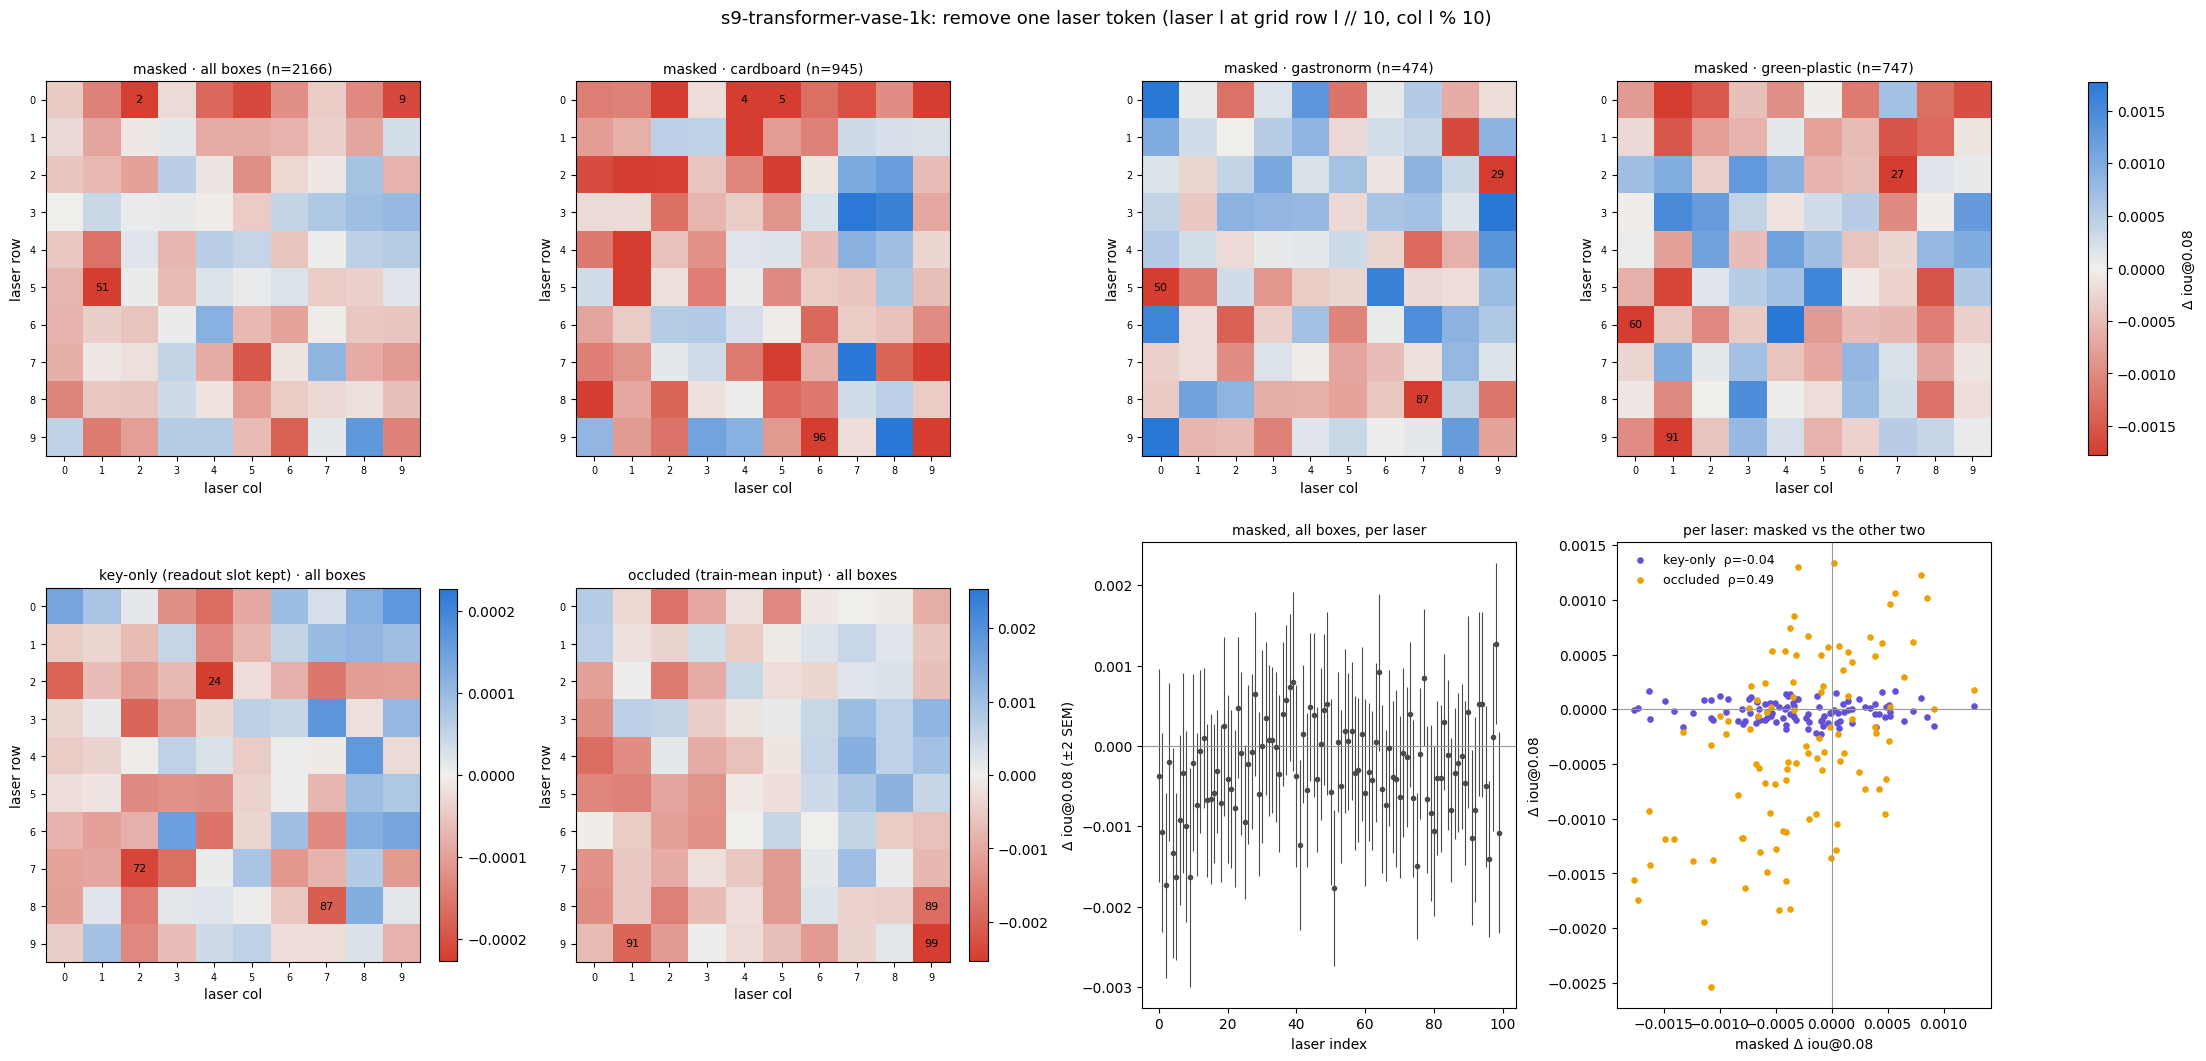

In [7]:
HIGHER = {"iou@0.08": True, "miss@0.08": False, "iou@0.5": True}[METRIC]       # red = removing it made the metric worse
DIV = LinearSegmentedColormap.from_list("div", ["#d43d2f", "#f0efec", "#2a78d6"] if HIGHER else ["#2a78d6", "#f0efec", "#d43d2f"])
BOXES = sorted(ev.box.unique())
BOX_COLOR = dict(zip(BOXES, ["#2a78d6", "#eb6834", "#1baf7a"]))                  # categorical slots 1-3
inbox = {b: (ev.box == b).values for b in BOXES}
sem = lambda a: a.std(0) / np.sqrt(len(a))                                         # standard error of the mean over samples

def grid(ax, a, title, v=None):  # (L,) -> heatmap on the 10x10 laser grid, the 3 most harmful-to-remove lasers numbered
    v = v or np.abs(a).max()
    im = ax.imshow(a.reshape(R, Cc), cmap=DIV, norm=TwoSlopeNorm(0, -v, v))
    for l in np.argsort(a if HIGHER else -a)[:3]: ax.text(l % Cc, l // Cc, l, ha="center", va="center", fontsize=8)
    ax.set_xticks(range(Cc)); ax.set_yticks(range(R)); ax.tick_params(labelsize=7); ax.set_xlabel("laser col"); ax.set_ylabel("laser row")
    ax.set_title(title, fontsize=10)
    return im

fig, axs = plt.subplots(2, 4, figsize=(22, 10.5), constrained_layout=True)
v = np.abs(D_LASER.mean(0)).max()
for ax, (name, a) in zip(axs[0], [("all boxes", D_LASER)] + [(b, D_LASER[inbox[b]]) for b in BOXES]):
    im = grid(ax, a.mean(0), f"masked · {name} (n={len(a)})", v)
fig.colorbar(im, ax=axs[0], shrink=0.8, label=f"Δ {METRIC}")
for ax, (name, a) in zip(axs[1], [("key-only (readout slot kept)", D_KEYONLY), ("occluded (train-mean input)", D_OCC_LASER)]):
    fig.colorbar(grid(ax, a.mean(0), f"{name} · all boxes"), ax=ax, shrink=0.8)
ax = axs[1, 2]
m, e = D_LASER.mean(0), sem(D_LASER)
ax.errorbar(np.arange(L), m, 2 * e, fmt="o", ms=3, color="#4a4a4a", elinewidth=0.8)
ax.axhline(0, color="#999", lw=0.8); ax.set_xlabel("laser index"); ax.set_ylabel(f"Δ {METRIC} (±2 SEM)"); ax.set_title("masked, all boxes, per laser", fontsize=10)
ax = axs[1, 3]
for name, a, c in [("key-only", D_KEYONLY, "#6250d6"), ("occluded", D_OCC_LASER, "#eda100")]:
    ax.scatter(m, a.mean(0), s=14, color=c, label=f"{name}  ρ={pd.Series(m).corr(pd.Series(a.mean(0)), method='spearman'):.2f}")
ax.axhline(0, color="#999", lw=0.8); ax.axvline(0, color="#999", lw=0.8); ax.legend(frameon=False, fontsize=9)
ax.set_xlabel(f"masked Δ {METRIC}"); ax.set_ylabel(f"Δ {METRIC}"); ax.set_title("per laser: masked vs the other two", fontsize=10)
fig.suptitle(f"{RUN}: remove one laser token (laser l at grid row l // {Cc}, col l % {Cc})", fontsize=13)
plt.show()

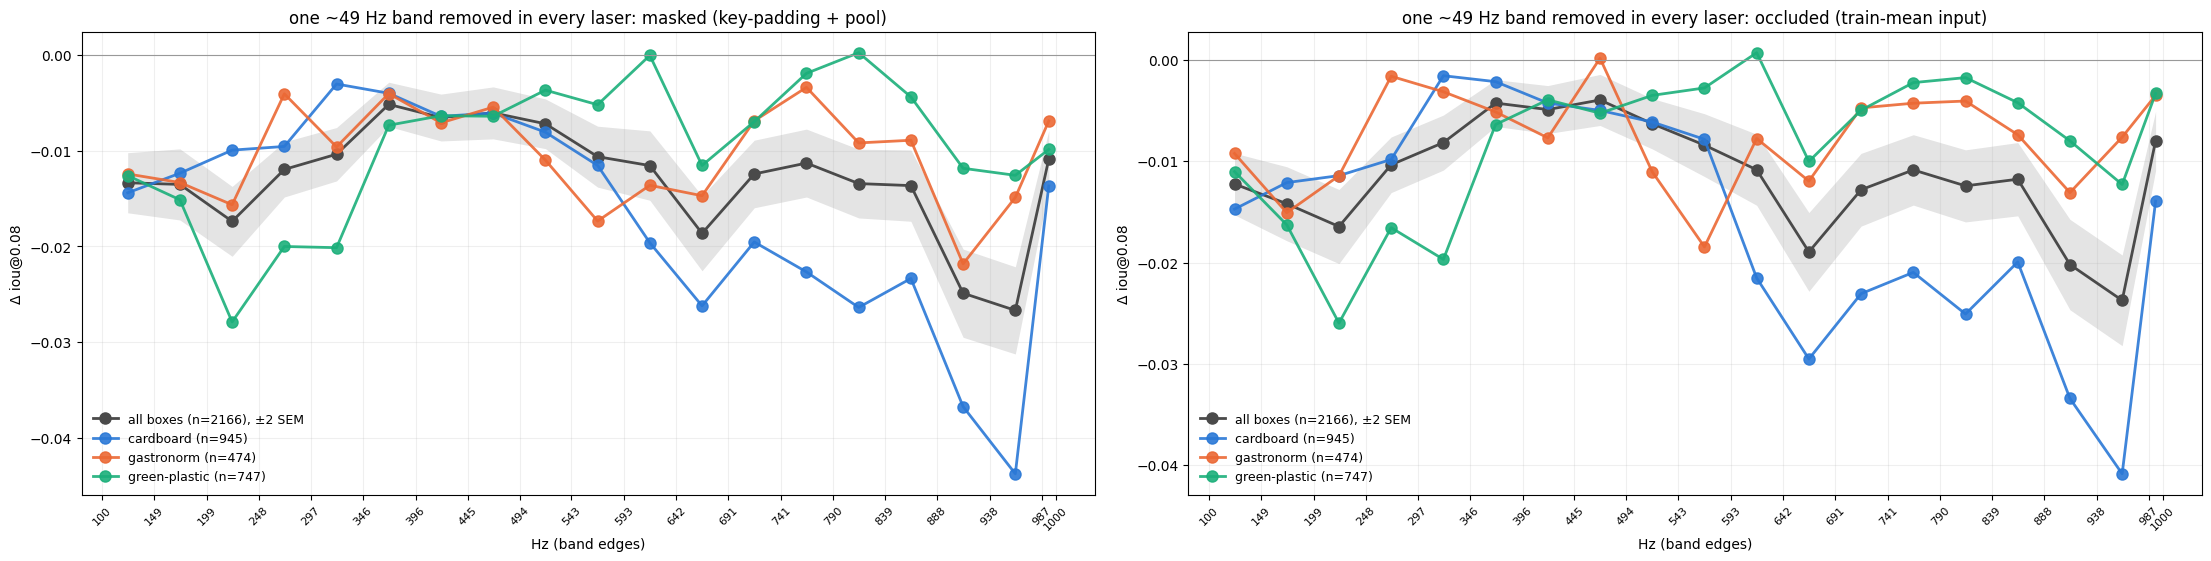

In [8]:
fc = (BAND_LO + BAND_HI) / 2                                                      # band centres, Hz
fig, axs = plt.subplots(1, 2, figsize=(22, 5.5), constrained_layout=True)
for ax, (name, D) in zip(axs, [("masked (key-padding + pool)", D_BAND), ("occluded (train-mean input)", D_OCC_BAND)]):
    m, e = D.mean(0), sem(D)
    ax.fill_between(fc, m - 2 * e, m + 2 * e, color="#4a4a4a", alpha=0.15, lw=0)
    ax.plot(fc, m, "o-", color="#4a4a4a", lw=2, ms=8, label=f"all boxes (n={len(D)}), ±2 SEM")
    for b in BOXES: ax.plot(fc, D[inbox[b]].mean(0), "o-", color=BOX_COLOR[b], lw=2, ms=8, alpha=0.9, label=f"{b} (n={inbox[b].sum()})")
    ax.axhline(0, color="#999", lw=0.8); ax.grid(alpha=0.2)
    ax.set_xticks(np.r_[BAND_LO, BAND_HI[-1]].round(), np.r_[BAND_LO, BAND_HI[-1]].round().astype(int), fontsize=8, rotation=45)
    ax.set_xlabel("Hz (band edges)"); ax.set_ylabel(f"Δ {METRIC}"); ax.set_title(f"one ~49 Hz band removed in every laser: {name}"); ax.legend(frameon=False, fontsize=9)
plt.show()

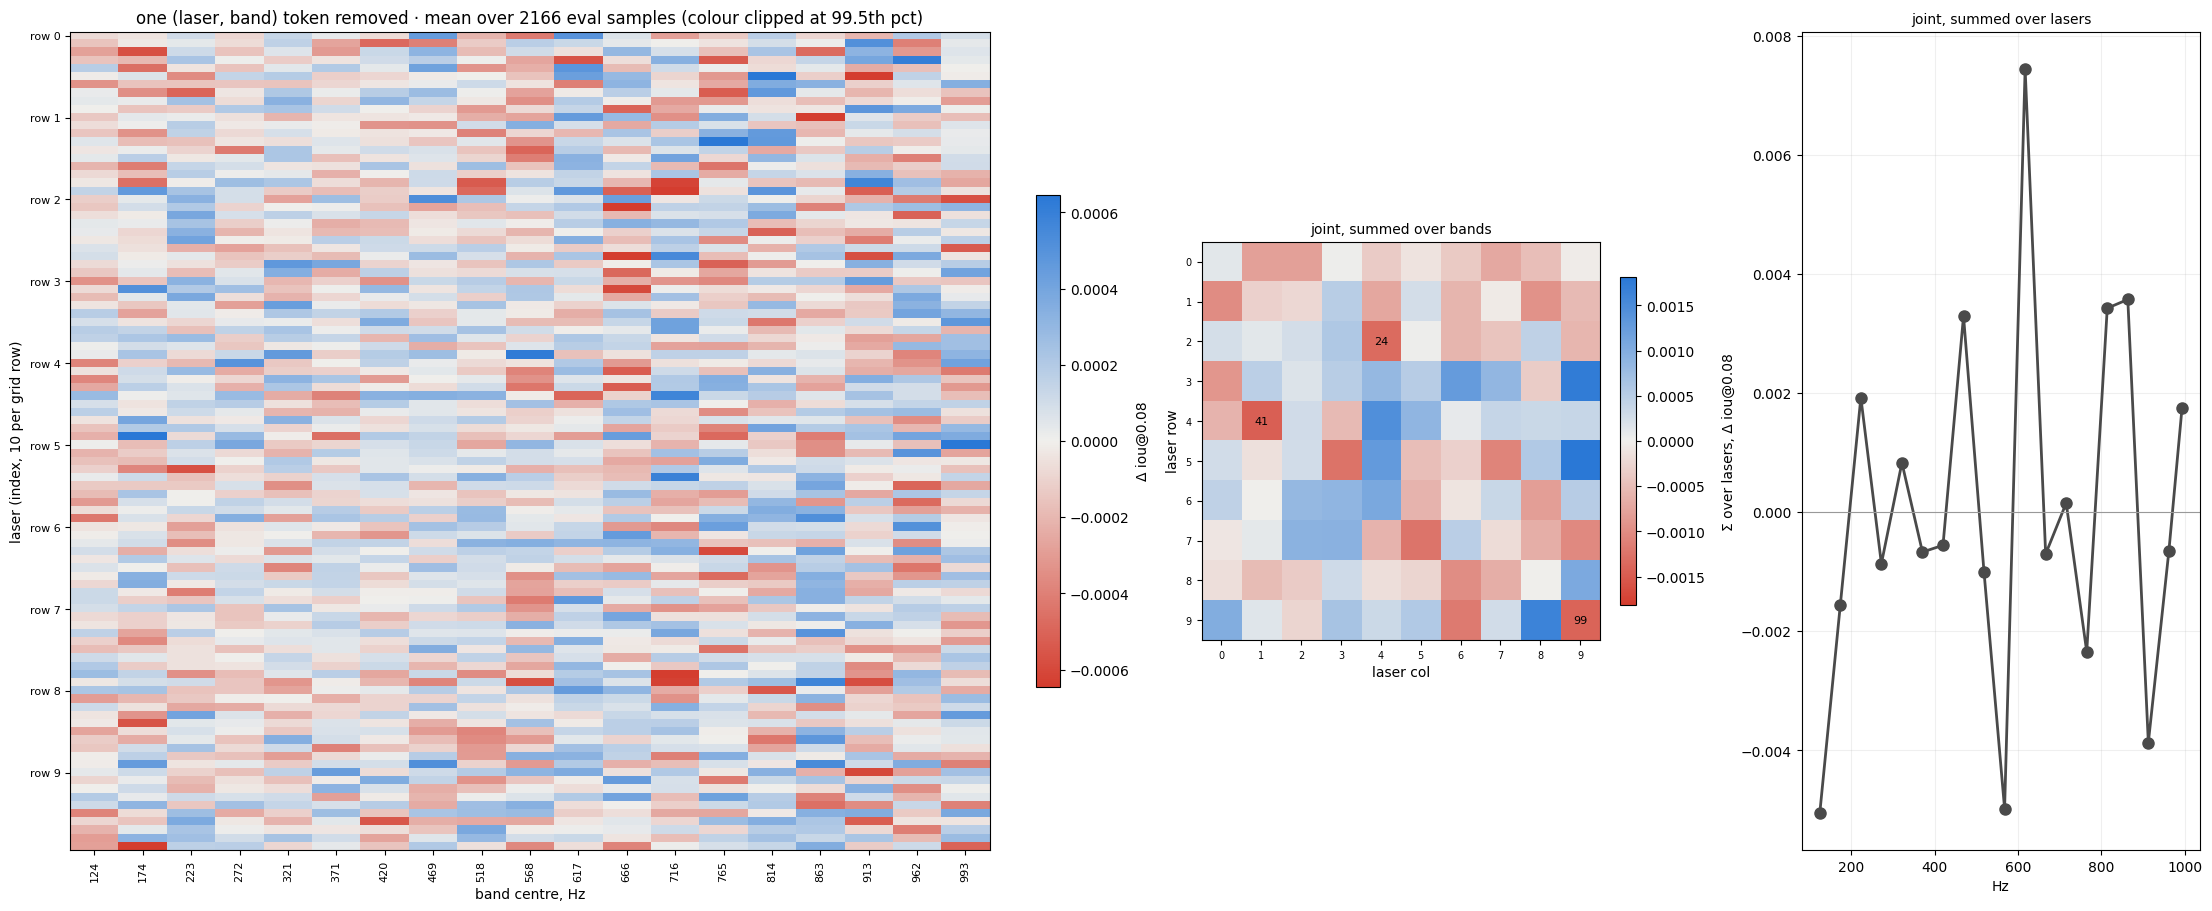

rank-1 share of the joint map 0.12;  Spearman: Σ_bands joint vs laser-masked 0.56, Σ_lasers joint vs band-masked 0.05


In [9]:
JM = D_JOINT[J].mean(0)                                                             # (L,NB) one (laser, band) token removed
v = np.percentile(np.abs(JM), 99.5)
fig, axs = plt.subplots(1, 3, figsize=(22, 9), constrained_layout=True, gridspec_kw=dict(width_ratios=[3, 1.3, 1.3]))
im = axs[0].imshow(JM, cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
axs[0].set_xticks(range(NB), fc.round().astype(int), rotation=90, fontsize=8); axs[0].set_yticks(range(0, L, Cc), [f"row {r}" for r in range(R)], fontsize=8)
axs[0].set_xlabel("band centre, Hz"); axs[0].set_ylabel("laser (index, 10 per grid row)")
axs[0].set_title(f"one (laser, band) token removed · mean over {len(J)} eval samples (colour clipped at 99.5th pct)")
fig.colorbar(im, ax=axs[0], shrink=0.6, label=f"Δ {METRIC}")
fig.colorbar(grid(axs[1], JM.sum(1), "joint, summed over bands"), ax=axs[1], shrink=0.4)
axs[2].plot(fc, JM.sum(0), "o-", color="#4a4a4a", lw=2, ms=8); axs[2].axhline(0, color="#999", lw=0.8)
axs[2].set_xlabel("Hz"); axs[2].set_ylabel(f"Σ over lasers, Δ {METRIC}"); axs[2].set_title("joint, summed over lasers", fontsize=10); axs[2].grid(alpha=0.2)
plt.show()

sv = np.linalg.svd(JM, compute_uv=False)
rho = lambda a, b: pd.Series(a).corr(pd.Series(b), method="spearman")
print(f"rank-1 share of the joint map {sv[0] ** 2 / (sv ** 2).sum():.2f};  Spearman: Σ_bands joint vs laser-masked {rho(JM.sum(1), D_LASER[J].mean(0)):.2f}, "
      f"Σ_lasers joint vs band-masked {rho(JM.sum(0), D_BAND[J].mean(0)):.2f}")

In [10]:
# importance = how much worse METRIC gets without the token (positive = the token helps), mean over the eval samples
sign = -1 if HIGHER else 1
imp = dict(laser=sign * D_LASER.mean(0), freq=sign * D_BAND.mean(0), joint=sign * JM,
           laser_keyonly=sign * D_KEYONLY.mean(0), laser_occ=sign * D_OCC_LASER.mean(0), freq_occ=sign * D_OCC_BAND.mean(0),
           laser_sem=sem(D_LASER), freq_sem=sem(D_BAND), **{f"laser_{b}": sign * D_LASER[inbox[b]].mean(0) for b in BOXES},
           **{f"freq_{b}": sign * D_BAND[inbox[b]].mean(0) for b in BOXES})
np.savez(OUT, **imp, band_lo_hz=BAND_LO, band_hi_hz=BAND_HI, grid_rc=np.array([R, Cc]), metric=METRIC, run=RUN, n=N, n_joint=len(J), clean=M0.mean())
print(f"saved {OUT.name}: {sorted(imp)}  (laser l at grid row l // {Cc}, col l % {Cc}; clean {METRIC} {M0.mean():.4f})")

top_l = np.argsort(-imp["laser"])[:10]
top_b = np.argsort(-imp["freq"])[:10]
display(pd.DataFrame(dict(laser=top_l, row=top_l // Cc, col=top_l % Cc, masked=imp["laser"][top_l], sem=imp["laser_sem"][top_l],
                          key_only=imp["laser_keyonly"][top_l], occluded=imp["laser_occ"][top_l])).round(4).set_index("laser"))
display(pd.DataFrame(dict(band=top_b, hz=[f"{BAND_LO[j]:.0f}-{BAND_HI[j]:.0f}" for j in top_b], masked=imp["freq"][top_b], sem=imp["freq_sem"][top_b],
                          occluded=imp["freq_occ"][top_b], **{b: imp[f"freq_{b}"][top_b] for b in BOXES})).round(4).set_index("band"))
tj = np.argsort(-imp["joint"], axis=None)[:10]
print("top (laser, band) tokens:", ", ".join(f"L{l}·{BAND_LO[j]:.0f}-{BAND_HI[j]:.0f}Hz {imp['joint'][l, j]:.4f}" for l, j in zip(*np.unravel_index(tj, JM.shape))))

saved imp_masking.npz: ['freq', 'freq_cardboard', 'freq_gastronorm', 'freq_green-plastic', 'freq_occ', 'freq_sem', 'joint', 'laser', 'laser_cardboard', 'laser_gastronorm', 'laser_green-plastic', 'laser_keyonly', 'laser_occ', 'laser_sem']  (laser l at grid row l // 10, col l % 10; clean iou@0.08 0.4640)


,row,col,masked,sem,key_only,occluded
laser,,,,,,
51,5,1,0.0018,0.0005,0.0000,0.0016
2,0,2,0.0017,0.0006,-0.0000,0.0017
9,0,9,0.0016,0.0007,-0.0002,0.0009
5,0,5,0.0016,0.0005,0.0001,0.0014
75,7,5,0.0015,0.0005,-0.0001,0.0012
96,9,6,0.0014,0.0005,0.0000,0.0012
4,0,4,0.0013,0.0007,0.0002,0.0002
41,4,1,0.0012,0.0005,0.0000,0.0014
91,9,1,0.0011,0.0005,-0.0001,0.0019


,hz,masked,sem,occluded,cardboard,gastronorm,green-plastic
band,,,,,,,
17,938-986,0.0267,0.0023,0.0237,0.0438,0.0149,0.0126
16,888-937,0.0249,0.0023,0.0202,0.0367,0.0218,0.0118
11,642-691,0.0186,0.0020,0.0189,0.0262,0.0147,0.0115
2,199-247,0.0174,0.0018,0.0164,0.0099,0.0156,0.0279
15,839-888,0.0136,0.0019,0.0118,0.0233,0.0089,0.0044
1,149-198,0.0135,0.0019,0.0142,0.0124,0.0133,0.0151
14,790-838,0.0134,0.0018,0.0124,0.0264,0.0092,-0.0002
0,100-149,0.0133,0.0016,0.0122,0.0144,0.0124,0.0126
12,691-740,0.0124,0.0018,0.0128,0.0195,0.0069,0.0070


top (laser, band) tokens: L27·642-691Hz 0.0009, L5·888-937Hz 0.0008, L10·839-888Hz 0.0007, L99·149-198Hz 0.0007, L78·691-740Hz 0.0006, L19·691-740Hz 0.0006, L21·642-691Hz 0.0006, L79·691-740Hz 0.0006, L18·691-740Hz 0.0006, L90·888-937Hz 0.0006
